In [1]:
import pandas as pd

cluster4 = pd.read_csv('./results/PPI/cluster4_annotations.tsv', sep='\t')

with open('./results/enrichment/cluster4_genes.txt', 'w') as f:
    f.write('\n'.join(cluster4['#node'].tolist()))

print(f"Cluster 4 genes saved: {len(cluster4)} genes")
print(cluster4['#node'].tolist())

Cluster 4 genes saved: 37 genes
['ABCG2', 'ANGPT1', 'CD151', 'CD34', 'CD44', 'CD69', 'COL4A3', 'COL4A4', 'COL6A6', 'EMCN', 'F13A1', 'HAS2', 'HYAL1', 'HYAL2', 'ICAM2', 'ICAM4', 'ITGA3', 'ITGA8', 'ITGAL', 'ITGB5', 'KLF2', 'LAMA2', 'LAMB1', 'LAMB2', 'LAMB3', 'LAMC2', 'LYVE1', 'MEX3A', 'MMRN1', 'NPNT', 'PDPN', 'PROX1', 'S1PR1', 'SLCO2B1', 'SRGN', 'TIE1', 'VWF']


In [3]:
import pandas as pd

degrees_c4 = pd.read_csv('./results/PPI/cluster4_degrees.tsv', sep='\t')

# Sort by degree and get top 5
top5_c4 = degrees_c4.sort_values('node_degree', ascending=False).head(5)
print("Top 5 hub genes by degree:")
print(top5_c4[['#node', 'node_degree']])

Top 5 hub genes by degree:
    #node  node_degree
4    CD44           19
16  ITGA3           13
17  ITGA8           13
19  ITGB5           11
21  LAMA2            9


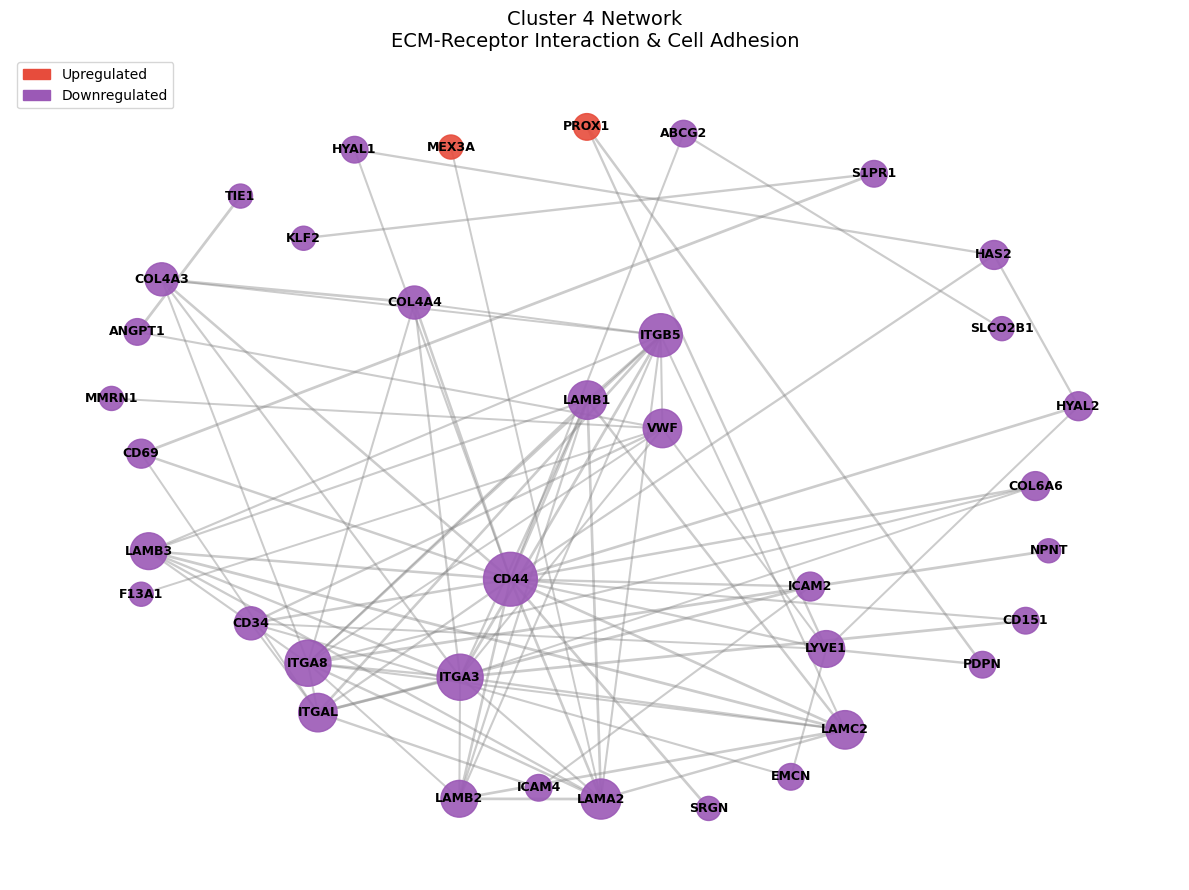

In [7]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

edges_c4 = pd.read_csv('./results/PPI/cluster4_edges.tsv', sep='\t')
consensus_df = pd.read_csv('./results/DEG/consensus_DEGs.csv')

# Build network
G4 = nx.Graph()
for _, row in edges_c4.iterrows():
    G4.add_edge(row['#node1'], row['node2'], weight=row['combined_score'])

# Color by direction
color_map_c4 = []
for node in G4.nodes():
    direction = consensus_df[consensus_df['Gene'] == node]['direction'].values
    if len(direction) > 0:
        color_map_c4.append('#e74c3c' if direction[0] == 'Up' else '#9b59b6')
    else:
        color_map_c4.append('grey')

# Normalize node sizes by degree
degrees = [degrees_c4[degrees_c4['#node'] == node]['node_degree'].values[0] 
           for node in G4.nodes()]
min_deg, max_deg = min(degrees), max(degrees)
node_sizes = [300 + (d - min_deg) / (max_deg - min_deg) * 1200 for d in degrees]

edge_weights = [G4[u][v]['weight'] * 2 for u, v in G4.edges()]

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G4, seed=42, k=2)

nx.draw_networkx_nodes(G4, pos, node_color=color_map_c4, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_edges(G4, pos, width=edge_weights, alpha=0.4, edge_color='grey')
nx.draw_networkx_labels(G4, pos, font_size=9, font_weight='bold')

legend = [mpatches.Patch(color='#e74c3c', label='Upregulated'),
          mpatches.Patch(color='#9b59b6', label='Downregulated'),
]
plt.legend(handles=legend, loc='upper left')

plt.title('Cluster 4 Network\nECM-Receptor Interaction & Cell Adhesion', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('./figures/cluster4_network.png', dpi=150)
plt.show()

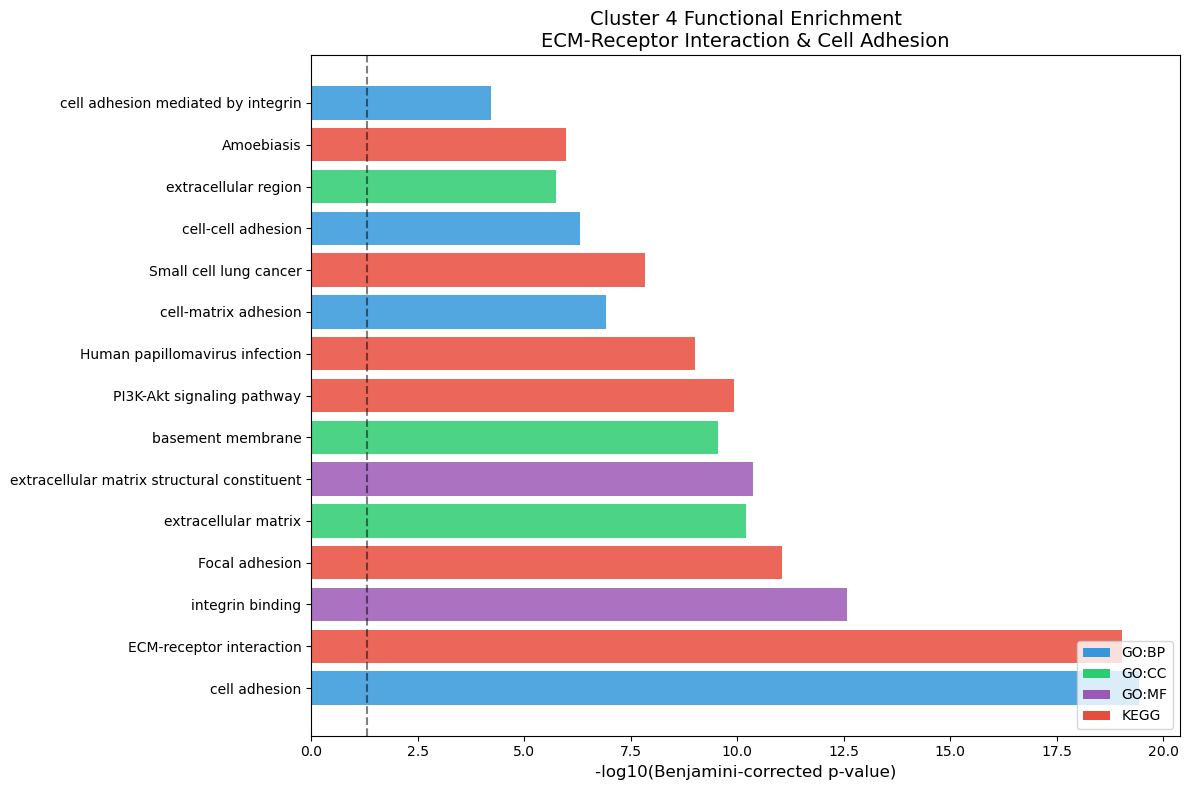


Records after category filter: 76
Category
GOTERM_BP_DIRECT    29
GOTERM_CC_DIRECT    22
KEGG_PATHWAY        17
GOTERM_MF_DIRECT     8
Name: count, dtype: int64

Top 15 terms:
            Category                                         Term  Count     Benjamini  Fold Enrichment
0   GOTERM_BP_DIRECT                                cell adhesion     22  3.780000e-20            18.12
1       KEGG_PATHWAY                     ECM-receptor interaction     14  9.130000e-20            62.24
3   GOTERM_MF_DIRECT                             integrin binding     12  2.710000e-13            39.90
5       KEGG_PATHWAY                               Focal adhesion     12  8.780000e-12            23.39
6   GOTERM_CC_DIRECT                         extracellular matrix     14  6.120000e-11            16.45
7   GOTERM_MF_DIRECT  extracellular matrix structural constituent     10  4.300000e-11            42.15
8   GOTERM_CC_DIRECT                            basement membrane      9  2.870000e-10         

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

cluster4_enrich = pd.read_csv('./results/enrichment/cluster4_enrichment.csv')

categories_keep = ['GOTERM_BP_DIRECT', 'GOTERM_CC_DIRECT', 
                   'GOTERM_MF_DIRECT', 'KEGG_PATHWAY']
filtered = cluster4_enrich[cluster4_enrich['Category'].isin(categories_keep)]
filtered = filtered.sort_values('P-Value').head(15)
filtered['-log10(FDR)'] = -np.log10(filtered['Benjamini'])

color_dict = {
    'GOTERM_BP_DIRECT': '#3498db',
    'GOTERM_CC_DIRECT': '#2ecc71',
    'GOTERM_MF_DIRECT': '#9b59b6',
    'KEGG_PATHWAY': '#e74c3c'
}
colors = [color_dict[cat] for cat in filtered['Category']]

plt.figure(figsize=(12, 8))
plt.barh(filtered['Term'], filtered['-log10(FDR)'], color=colors, alpha=0.85)
plt.xlabel('-log10(Benjamini-corrected p-value)', fontsize=12)
plt.title('Cluster 4 Functional Enrichment\nECM-Receptor Interaction & Cell Adhesion', fontsize=14)
plt.axvline(x=-np.log10(0.05), color='black', linestyle='--', alpha=0.5)

legend_elements = [Patch(facecolor='#3498db', label='GO:BP'),
                   Patch(facecolor='#2ecc71', label='GO:CC'),
                   Patch(facecolor='#9b59b6', label='GO:MF'),
                   Patch(facecolor='#e74c3c', label='KEGG')]
plt.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig('./figures/cluster4_enrichment.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nRecords after category filter: {len(cluster4_enrich[cluster4_enrich['Category'].isin(categories_keep)])}")
print(cluster4_enrich[cluster4_enrich['Category'].isin(categories_keep)]['Category'].value_counts())
print("\nTop 15 terms:")
print(filtered[['Category', 'Term', 'Count', 'Benjamini', 'Fold Enrichment']].to_string())

In [11]:
import numpy as np

filtered_all_c4 = cluster4_enrich[cluster4_enrich['Category'].isin(categories_keep)].copy()
filtered_all_c4 = filtered_all_c4[filtered_all_c4['Benjamini'] < 0.05]
filtered_all_c4 = filtered_all_c4.sort_values('Benjamini')
filtered_all_c4['-log10(Benjamini)'] = -np.log10(filtered_all_c4['Benjamini'])
filtered_all_c4.to_csv('./results/enrichment/cluster4_enrichment_filtered.csv', index=False)
print(f"Cluster 4: {len(filtered_all_c4)} significant terms saved")

Cluster 4: 54 significant terms saved
